# 03 · Control vs AD Classification

**Research questions**
1. Can a mouse's behavior tell us whether it is a **Control** (C57BL/6J) or an **AD-model** (APP<sup>NL-G-F</sup>) mouse?
2. Which behavioral characteristics separate the groups most?
3. Does **condition-dependent** behavior (how behavior changes with pellet size or distance) discriminate better than **overall** behavior proportions?
4. Do the differences point to changes in **cost sensitivity** or **behavioral flexibility**?

## The key methodological point: we have 41 samples, not 5,000

The dataset has ~5,400 trials, but the label we want to predict (Control or AD) belongs to the **mouse**, not to the trial. All trials of one mouse share the same label. So the number of independent samples is the number of mice: **41 (28 Control, 13 AD)**.

Therefore, in this notebook:
* each mouse becomes **one row** with a set of summary features ("mouse-level features");
* every model is evaluated on **mice it has not seen**;
* we keep models **small** (few features, strong regularization), because 41 samples cannot support complex models.

**Framing:** the features summarize each mouse's *complete* behavioral record. The question is therefore "can a completed behavioral profile identify the genotype?", not "can we predict the genotype early".

## Plan
1. Load data
2. Why trial-level classification is misleading (a demonstration)
3. Building mouse-level features
4. A first look: how much does each feature differ between groups?
5. Validation strategy for 41 mice
6. Classification with different feature sets
7. Is it better than chance? Permutation tests
8. Which features drive the separation?
9. Summary and limitations

## 0. Setup

In [1]:
import sys
sys.path.insert(0, "..")

import inspect
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import modeling, evaluation, feature_engineering as fe
from src import visualization as viz

viz.set_plot_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
warnings.filterwarnings("ignore", category=UserWarning)

TABLES = "../results/tables"
import os
os.makedirs(TABLES, exist_ok=True)

df = pd.read_csv("../data/processed/trials_clean.csv")
status = df.groupby("Id")["Status"].first()
print(status.value_counts())

Status
Control    28
AD         13
Name: count, dtype: int64


## 1. Why trial-level classification is misleading

The original notebook classified **trials** as Control or AD, with a random train/test split of trials. Let us repeat that idea with a random forest on trial-level variables (task condition, behavior, and movement), and compare two ways of splitting the data:
* **trial-level 5-fold CV:** trials are shuffled, so every mouse has trials in both the training and the test folds;
* **mouse-level 5-fold CV** (`StratifiedGroupKFold`): all trials of a mouse are in the same fold, so the test mice are new.

We measure **ROC-AUC**: the probability that a randomly chosen AD sample gets a higher "AD score" than a randomly chosen Control sample. 0.5 = chance, 1.0 = perfect separation.

In [2]:
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_score

trial_categorical = ["Length", "Texture", "SizeCategory", "Behavior"]
trial_numeric = ["DelayToStart", "InitialVelOut", "AtFoodArea_s", "InboundVel"]
trial_features = trial_categorical + trial_numeric
is_ad = (df["Status"] == "AD").astype(int)

forest, _ = modeling.make_model("Random forest", trial_categorical, trial_numeric)
forest.set_params(classifier__min_samples_leaf=1, classifier__n_jobs=-1)

trial_level = cross_val_score(forest, df[trial_features], is_ad,
                              cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0), scoring="roc_auc")
mouse_level = cross_val_score(forest, df[trial_features], is_ad,
                              cv=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0),
                              groups=df["Id"], scoring="roc_auc")
print(f"Trial-level CV  (same mice in training and test): AUC = {trial_level.mean():.3f}")
print(f"Mouse-level CV  (test mice are new):              AUC = {mouse_level.mean():.3f}")

Trial-level CV  (same mice in training and test): AUC = 0.795
Mouse-level CV  (test mice are new):              AUC = 0.665


**How to read the output:** the same model looks much better when the test trials come from mice it has already seen (AUC ≈ 0.80) than when the test mice are new (≈ 0.67). With trial-level splitting, the model partly learns to **recognize individual mice** (their typical speed, delay, habits). Since every trial of a mouse carries the mouse's label, recognizing the mouse is enough to "predict" its group. That does not generalize to new animals.

There is a second, subtler problem: even the mouse-level CV here treats ~5,000 trials as samples. Mice with many trials dominate the training, and the score is computed over trials, not mice. The honest design is to summarize each mouse first and then classify **mice**. That is what the rest of this notebook does.

## 2. Building mouse-level features

**Goal:** describe each mouse with a small number of interpretable numbers.

**Guiding rule: compare like with like.** Behavior depends strongly on the condition (notebook 01), and the mice did not all experience the same conditions: 13 mice never received hard food, and 5 never ran long-soft. A feature like "overall carry rate across all trials" therefore mixes *behavior* with *which conditions the mouse happened to experience*. So most features are computed **within the short-soft condition**, which every mouse experienced (with at least 8 trials per pellet size).

| Family | Features | Biological idea |
|---|---|---|
| **Overall proportions** | `all_Eat`, `all_Carry`, `all_NosePoke`, `all_NoLeave` (all trials) | simple baseline; confounded by condition coverage |
| **Short-soft choices** | `ss_Eat`, `ss_Carry`, `ss_NosePoke`, `ss_NoLeave` | what the mouse does in the easiest, shared condition |
| **Size sensitivity** | `ss_size_effect_Eat`, `ss_size_effect_Carry` = P(large) − P(small) | does the mouse adapt its choice to the pellet? (*cost–benefit sensitivity*) |
| **Variability** | `ss_switch_rate`: fraction of trials whose behavior differs from the previous trial | *behavioral flexibility* (or inconsistency) |
| **Movement on Eat trials** | median start delay, initial outbound speed, time at food, inbound speed; fraction of trials with back-and-forth | *how* the mouse performs the same behavior |
| **Distance sensitivity** (36 mice) | `soft_distance_effect_Eat/Carry/NoLeave` = P(long-soft) − P(short-soft) | reaction to a higher travel cost (*cost sensitivity*) |

Two important details:
* **Movement is summarized within Eat trials only.** Movement differs strongly between behaviors (notebook 01, section 10.2). If one group simply ate more often, an all-trial average would differ even if each behavior were performed identically. Within Eat trials we compare the same behavior. (Here time at food is allowed: it is not used to *identify* Eat, it describes how long the mice eat.)
* **Distance features exist for only 36 mice** (10 AD, 26 Control). Five mice never ran long-soft. These features are analyzed in a separate subset rather than imputed: imputing would invent the very behavior we want to measure.

In [3]:
print(inspect.getsource(fe.size_effects))
print(inspect.getsource(fe.movement_on_eat_trials))

def size_effects(trials, prefix):
    """How much the choice changes from small to large pellets, per mouse:
    P(behavior | large) - P(behavior | small).
    A positive Carry value means the mouse carries more when the pellet is large."""
    small = behavior_proportions(trials[trials["SizeCategory"] == "small"], "p")
    large = behavior_proportions(trials[trials["SizeCategory"] == "large"], "p")
    effects = pd.DataFrame(index=small.index)
    for behavior in ["Eat", "Carry"]:
        effects[f"{prefix}_size_effect_{behavior}"] = large[f"p_{behavior}"] - small[f"p_{behavior}"]
    return effects

def movement_on_eat_trials(trials, prefix):
    """Movement summaries computed on EAT trials only.

    Restricting to one behavior is essential: movement differs strongly
    between behaviors (notebook 01, section 10.2). If AD mice simply ate
    more often, an all-trial average would differ between groups even if
    each behavior looked identical. Within Eat trials, a group difference

In [4]:
short_soft = df[df["Condition"] == "short-soft"]
long_soft = df[df["Condition"] == "long-soft"]

features = pd.concat([
    fe.behavior_proportions(df, "all"),
    fe.behavior_proportions(short_soft, "ss"),
    fe.size_effects(short_soft, "ss"),
    fe.switch_rate(short_soft, "ss"),
    fe.movement_on_eat_trials(short_soft, "ss_eat"),
    fe.distance_effects(short_soft, long_soft, "soft"),
], axis=1)
features["Status"] = status

FEATURE_FAMILIES = {
    "Overall proportions": [c for c in features if c.startswith("all_")],
    "Short-soft choices": ["ss_Eat", "ss_Carry", "ss_NosePoke", "ss_NoLeave",
                           "ss_size_effect_Eat", "ss_size_effect_Carry", "ss_switch_rate"],
    "Movement (Eat trials)": [c for c in features if c.startswith("ss_eat_")],
    "Distance sensitivity": [c for c in features if c.startswith("soft_")],
}

print("Mouse-level table:", features.shape[0], "mice x", features.shape[1] - 1, "features")
print("\nMissing values per feature:")
print(features.isna().sum()[features.isna().sum() > 0])
features.round(3).head()

Mouse-level table: 41 mice x 19 features

Missing values per feature:
soft_distance_effect_Eat        5
soft_distance_effect_Carry      5
soft_distance_effect_NoLeave    5
dtype: int64


,all_Eat,all_Carry,all_NosePoke,all_NoLeave,ss_Eat,ss_Carry,ss_NosePoke,ss_NoLeave,ss_size_effect_Eat,ss_size_effect_Carry,ss_switch_rate,ss_eat_delay_median,ss_eat_initial_speed_out_median,ss_eat_time_at_food_median,ss_eat_speed_in_median,ss_eat_back_and_forth_fraction,soft_distance_effect_Eat,soft_distance_effect_Carry,soft_distance_effect_NoLeave,Status
Id,,,,,,,,,,,,,,,,,,,,
3208,0.700,0.000,0.300,0.000,0.700,0.000,0.300,0.0,-0.450,0.000,0.417,4.050,43.286,23.033,11.198,0.375,NaN,NaN,NaN,AD
3376,0.791,0.042,0.167,0.000,0.574,0.147,0.279,0.0,-0.147,0.176,0.431,1.700,27.523,14.200,13.268,0.487,0.264,-0.147,0.000,Control
3385,0.255,0.588,0.000,0.157,0.426,0.574,0.000,0.0,-0.839,0.839,0.581,43.000,11.172,20.383,26.695,0.000,-0.236,0.156,0.079,Control
3446,0.338,0.417,0.185,0.060,0.493,0.358,0.149,0.0,-0.582,0.586,0.560,6.767,16.215,10.967,21.408,0.273,-0.221,0.082,0.017,Control
3448,0.789,0.123,0.066,0.022,0.657,0.239,0.104,0.0,-0.497,0.351,0.510,6.900,23.994,20.017,25.580,0.205,0.186,-0.167,0.000,Control


**How to read the output:** one row per mouse. Only the three distance features have missing values (the 5 mice without long-soft); all other features exist for all 41 mice.

**A note on proportions:** within a family the four behavior proportions add up to 1, so any one of them can be computed from the other three. With regularized logistic regression this is harmless (regularization handles the redundancy), but it means that the *individual* coefficients of these four features should not be over-interpreted.

## 3. A first look: how different are the groups on each feature?

**Goal:** before building models, look at each feature separately.

For each feature we compute a **univariate AUC**: the probability that a randomly chosen AD mouse has a *higher* value than a randomly chosen Control mouse.
* 0.5 = no difference;
* close to 1 = AD mice have higher values;
* close to 0 = AD mice have lower values.

This is the same quantity as the Mann–Whitney U statistic divided by (n<sub>AD</sub> × n<sub>Control</sub>). Because each mouse is one data point, this comparison respects the repeated-measures structure.

In [5]:
from scipy.stats import mannwhitneyu

univariate_rows = []
for family, columns in FEATURE_FAMILIES.items():
    for column in columns:
        values = features[[column, "Status"]].dropna()
        ad = values.loc[values["Status"] == "AD", column]
        control = values.loc[values["Status"] == "Control", column]
        test = mannwhitneyu(ad, control)
        univariate_rows.append({
            "family": family, "feature": column,
            "median Control": control.median(), "median AD": ad.median(),
            "AUC (AD > Control)": test.statistic / (len(ad) * len(control)),
            "p (Mann-Whitney)": test.pvalue,
            "n AD / Control": f"{len(ad)} / {len(control)}",
        })
univariate = pd.DataFrame(univariate_rows)
univariate.round(3)

,family,feature,median Control,median AD,AUC (AD > Control),p (Mann-Whitney),n AD / Control
0,Overall proportions,all_Eat,0.601,0.585,0.525,0.812,13 / 28
1,Overall proportions,all_Carry,0.075,0.042,0.419,0.415,13 / 28
2,Overall proportions,all_NosePoke,0.156,0.108,0.486,0.900,13 / 28
3,Overall proportions,all_NoLeave,0.020,0.058,0.588,0.370,13 / 28
4,Short-soft choices,ss_Eat,0.513,0.700,0.712,0.032,13 / 28
5,Short-soft choices,ss_Carry,0.125,0.000,0.335,0.090,13 / 28
6,Short-soft choices,ss_NosePoke,0.176,0.200,0.484,0.877,13 / 28
7,Short-soft choices,ss_NoLeave,0.000,0.000,0.354,0.067,13 / 28
8,Short-soft choices,ss_size_effect_Eat,-0.364,-0.409,0.516,0.878,13 / 28
9,Short-soft choices,ss_size_effect_Carry,0.195,0.000,0.321,0.066,13 / 28


**Caveat:** this table contains 19 tests. With 19 tests, about one feature is expected to reach p < 0.05 by chance alone (*multiple comparisons*). The p-values are a rough guide, not proof. The classification analysis below asks the more relevant question: can the features *together* identify the group of **new** mice?

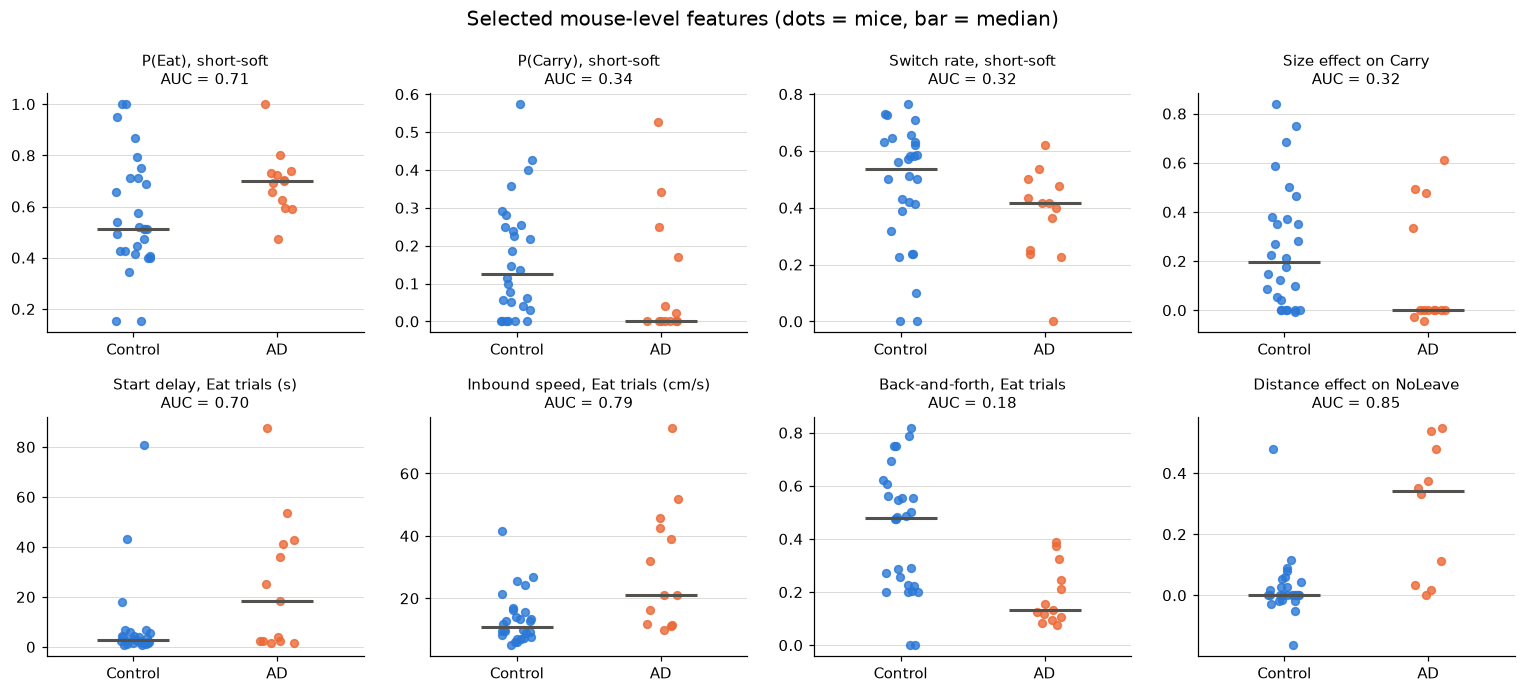

In [6]:
selected = ["ss_Eat", "ss_Carry", "ss_switch_rate", "ss_size_effect_Carry",
            "ss_eat_delay_median", "ss_eat_speed_in_median", "ss_eat_back_and_forth_fraction",
            "soft_distance_effect_NoLeave"]
labels = {
    "ss_Eat": "P(Eat), short-soft", "ss_Carry": "P(Carry), short-soft",
    "ss_switch_rate": "Switch rate, short-soft", "ss_size_effect_Carry": "Size effect on Carry",
    "ss_eat_delay_median": "Start delay, Eat trials (s)", "ss_eat_speed_in_median": "Inbound speed, Eat trials (cm/s)",
    "ss_eat_back_and_forth_fraction": "Back-and-forth, Eat trials", "soft_distance_effect_NoLeave": "Distance effect on NoLeave",
}

fig, axes = plt.subplots(2, 4, figsize=(14, 6.4))
rng = np.random.default_rng(0)
for ax, column in zip(axes.flat, selected):
    for g_index, group in enumerate(viz.GROUP_ORDER):
        values = features.loc[features["Status"] == group, column].dropna()
        jitter = rng.uniform(-0.12, 0.12, size=len(values))
        ax.scatter(g_index + jitter, values, s=26, alpha=0.8, color=viz.GROUP_COLORS[group])
        ax.hlines(values.median(), g_index - 0.25, g_index + 0.25, color=viz.NEUTRAL_DARK, linewidth=2)
    auc = univariate.set_index("feature").loc[column, "AUC (AD > Control)"]
    ax.set_title(f"{labels[column]}\nAUC = {auc:.2f}", fontsize=10)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(viz.GROUP_ORDER)
    ax.set_xlim(-0.6, 1.6)
fig.suptitle("Selected mouse-level features (dots = mice, bar = median)")
fig.tight_layout()
viz.save_figure(fig, "03_mouse_features")
plt.show()

**How to read the output:**
* **Overall proportions show no group difference** (AUCs 0.42–0.59). Across all trials, AD and Control mice eat, carry, poke and stay home in similar proportions. Notebook 01 explains why: the differences appear in *specific conditions*, and pooling all conditions (which also differ in coverage between mice) averages them out.
* **Short-soft choices:** AD mice eat more on the spot (median 0.70 vs 0.51; AUC 0.71) and most of them **almost never carry** in short-soft. Only 4 of 13 AD mice carry at all. Consequently their size effect on Carry is ~0: unlike most Control mice, they do not start carrying when the pellet is large. Their switch rate is lower (0.42 vs 0.54): their choices vary less from trial to trial.
* **Movement on Eat trials:** AD mice return home faster (AUC 0.79), make far fewer back-and-forth trips (13 % vs 48 % of Eat trials; AUC 0.18, i.e. strongly *lower* in AD), and about half of them wait long before leaving (start delay; bimodal, as in notebook 01).
* **Distance sensitivity (36 mice):** the strongest single feature. When the distance increases, many AD mice start staying at home (median NoLeave increase +0.34 vs 0.00; AUC 0.85) and eat less (AUC 0.17). The AD values are bimodal: 6 of 10 mice react strongly, 4 hardly at all. One Control mouse reacts like the AD mice.

## 4. Validation strategy for 41 mice

**Repeated stratified 5-fold cross-validation.**
* *5-fold:* the 41 mice are split into 5 groups; each group is the test set once, and the model is trained on the other ~33 mice.
* *Stratified:* every fold keeps the AD/Control ratio (~1/3 AD), so no test fold is accidentally all-Control.
* *Repeated (20×):* with 41 mice, the result depends noticeably on *which* mice land in which fold. Repeating with 20 different random splits and averaging gives a stable estimate. The spread across repetitions shows how much the split matters.
* *Nested:* the regularization strength `C` of logistic regression is chosen inside each training set (inner 4-fold CV), never on the test mice.

**Why not leave-one-mouse-out here?** ROC-AUC compares AD and Control mice *against each other*, so it cannot be computed within a test set of one mouse. We could pool the predictions, but leave-one-out estimates are known to have high variance. Repeated k-fold is the standard, more stable choice for small samples.

**Metrics:** ROC-AUC (threshold-free) and balanced accuracy (with a 0.5 probability threshold; chance = 0.5).

**Models:**
* **L2-regularized logistic regression** (main model): one coefficient per feature. With 41 samples, regularization is essential. It shrinks coefficients toward zero and prevents the model from fitting noise.
* **Random forest** (comparison): can capture non-linear patterns, but with 41 mice it has little data to learn them from.

In [7]:
print(inspect.getsource(evaluation.repeated_cv_mouse_level))

def repeated_cv_mouse_level(model, grid, X, y, n_repeats=20, n_splits=5, seed=0):
    """Repeated stratified k-fold cross-validation with one row per MOUSE.

    In each repetition the mice are split into `n_splits` folds in a new
    random way (stratified: every fold keeps the AD/Control ratio). Every
    mouse gets one out-of-fold probability of being AD, and we compute the
    ROC-AUC and balanced accuracy over all mice. Repeating the split shows
    how much the result depends on the particular random split.

    If `grid` is not empty, the hyperparameters are tuned INSIDE each
    training set with an inner stratified 4-fold CV (nested CV).

    Returns (scores, mean_probability):
      scores           - one row per repetition (auc, balanced_accuracy)
      mean_probability - each mouse's out-of-fold P(AD), averaged over repetitions
    """
    from sklearn.metrics import roc_auc_score
    from sklearn.model_selection import StratifiedKFold

    score_rows = []
    all_probabili

## 5. Classification with different feature sets

We compare feature sets of increasing richness. The first four use all 41 mice. The distance features use the 36 mice that ran both distances; for a fair comparison, the short-soft feature sets are also re-run on these same 36 mice.

In [8]:
y_all = (features["Status"] == "AD").astype(int)
has_distance = features["soft_distance_effect_NoLeave"].notna()

FEATURE_SETS = {
    # name: (columns, which mice)
    "Overall proportions":                 (FEATURE_FAMILIES["Overall proportions"], "all 41"),
    "Short-soft choices":                  (FEATURE_FAMILIES["Short-soft choices"], "all 41"),
    "Movement (Eat trials)":               (FEATURE_FAMILIES["Movement (Eat trials)"], "all 41"),
    "Choices + Movement":                  (FEATURE_FAMILIES["Short-soft choices"] + FEATURE_FAMILIES["Movement (Eat trials)"], "all 41"),
    "Short-soft choices (36 mice)":        (FEATURE_FAMILIES["Short-soft choices"], "36 with distance"),
    "Distance sensitivity":                (FEATURE_FAMILIES["Distance sensitivity"], "36 with distance"),
    "Choices + Distance":                  (FEATURE_FAMILIES["Short-soft choices"] + FEATURE_FAMILIES["Distance sensitivity"], "36 with distance"),
}

result_rows = []
cv_scores = {}
cv_probabilities = {}
for set_name, (columns, mice) in FEATURE_SETS.items():
    rows = has_distance if mice == "36 with distance" else pd.Series(True, index=features.index)
    X = features.loc[rows, columns]
    y = y_all[rows]
    for model_name in ["Logistic regression", "Random forest"]:
        model, grid = modeling.make_group_classifier(model_name)
        scores, probability = evaluation.repeated_cv_mouse_level(model, grid, X, y, n_repeats=20)
        cv_scores[(set_name, model_name)] = scores
        cv_probabilities[(set_name, model_name)] = probability
        result_rows.append({
            "feature set": set_name, "mice": f"{y.sum()} AD / {(1 - y).sum()} Ctrl",
            "n features": len(columns), "model": model_name,
            "AUC mean": scores["auc"].mean(), "AUC SD (splits)": scores["auc"].std(),
            "balanced accuracy": scores["balanced_accuracy"].mean(),
        })

results = pd.DataFrame(result_rows)
results.round(3)

,feature set,mice,n features,model,AUC mean,AUC SD (splits),balanced accuracy
0,Overall proportions,13 AD / 28 Ctrl,4,Logistic regression,0.505,0.054,0.519
1,Overall proportions,13 AD / 28 Ctrl,4,Random forest,0.505,0.061,0.540
2,Short-soft choices,13 AD / 28 Ctrl,7,Logistic regression,0.591,0.061,0.620
3,Short-soft choices,13 AD / 28 Ctrl,7,Random forest,0.744,0.026,0.684
4,Movement (Eat trials),13 AD / 28 Ctrl,5,Logistic regression,0.805,0.043,0.729
5,Movement (Eat trials),13 AD / 28 Ctrl,5,Random forest,0.885,0.030,0.793
6,Choices + Movement,13 AD / 28 Ctrl,12,Logistic regression,0.893,0.030,0.810
7,Choices + Movement,13 AD / 28 Ctrl,12,Random forest,0.913,0.027,0.810
8,Short-soft choices (36 mice),10 AD / 26 Ctrl,7,Logistic regression,0.540,0.067,0.584
9,Short-soft choices (36 mice),10 AD / 26 Ctrl,7,Random forest,0.716,0.029,0.734


**How to read the output:**
* **Overall proportions: AUC 0.50, chance.** This answers research question 3 directly: *overall* behavior does not discriminate.
* **Condition-dependent behavior does.** Distance sensitivity alone (3 features) reaches **AUC 0.81** (36 mice). Short-soft choices reach 0.59 with logistic regression but **0.74 with the random forest**. That gap suggests a *non-linear* pattern, for example "carries **never**" being informative in a way a straight-line model cannot express.
* **Movement on Eat trials** gives AUC 0.81 (logistic regression) to 0.89 (random forest), and **Choices + Movement** reaches **0.89–0.91**, the highest values. See the important caveat on movement in section 9.
* **More features is not always better:** Choices + Distance (10 features, 36 mice) is *worse* than Distance alone with logistic regression (0.73 vs 0.81). Adding seven weaker features to only 36 samples adds noise that regularization cannot fully remove. This is a typical small-sample effect.
* **Split-to-split variability** (AUC SD 0.02–0.07) is modest: the ranking of feature sets does not depend on the random split.

*Caution about selection:* we compared 7 feature sets × 2 models. Picking the best of 14 results and reporting its AUC would be slightly optimistic. The permutation tests below therefore focus on pre-defined feature families, and we interpret the *pattern* across sets rather than the single best number.

## 6. Is it better than chance? Permutation tests

The AUC spread across repetitions (section 5) tells us how much the result depends on the random split, but **not** whether it could have arisen by chance. With 41 mice, a model can reach an AUC of 0.6–0.7 on pure noise just by luck.

**Permutation test:**
1. Shuffle the Control/AD labels across mice. Any real link between behavior and group is destroyed, but everything else (number of mice, features, class ratio) stays the same.
2. Run the same cross-validation and record the AUC.
3. Repeat 500 times. This gives the **null distribution**: the AUC values we would see if behavior carried no information about the group.
4. **p-value** = fraction of shuffled AUCs that are at least as high as the real AUC.

To keep this fast, the regularization strength is fixed (C = 0.1) instead of tuned. The real AUC is recomputed with the same fixed setting, so both sides of the comparison use the identical procedure.

In [9]:
fixed_model, _ = modeling.make_group_classifier("Logistic regression")
fixed_model.set_params(classifier__C=0.1)

sets_to_test = ["Overall proportions", "Short-soft choices", "Movement (Eat trials)",
                "Choices + Movement", "Distance sensitivity"]
permutation_rows = []
null_distributions = {}
for set_name in sets_to_test:
    columns, mice = FEATURE_SETS[set_name]
    rows = has_distance if mice == "36 with distance" else pd.Series(True, index=features.index)
    observed, null, p_value = evaluation.permutation_test_auc(
        fixed_model, features.loc[rows, columns], y_all[rows], n_permutations=500, n_repeats=5)
    null_distributions[set_name] = (observed, null)
    permutation_rows.append({"feature set": set_name, "AUC (fixed C)": observed,
                             "null 95th percentile": np.quantile(null, 0.95), "p-value": p_value})
permutation_table = pd.DataFrame(permutation_rows)
permutation_table.round(3)

,feature set,AUC (fixed C),null 95th percentile,p-value
0,Overall proportions,0.474,0.665,0.515
1,Short-soft choices,0.623,0.684,0.116
2,Movement (Eat trials),0.847,0.678,0.002
3,Choices + Movement,0.904,0.685,0.002
4,Distance sensitivity,0.805,0.699,0.006


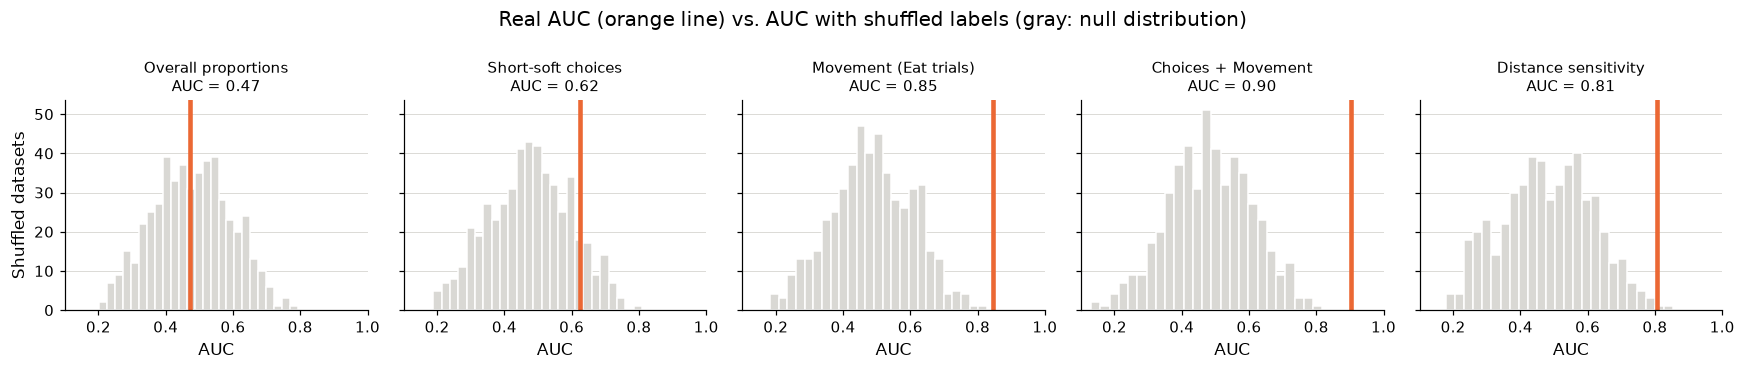

In [10]:
fig, axes = plt.subplots(1, len(sets_to_test), figsize=(16, 3.4), sharey=True)
for ax, set_name in zip(axes, sets_to_test):
    observed, null = null_distributions[set_name]
    ax.hist(null, bins=25, color=viz.NEUTRAL_LIGHT, edgecolor="white")
    ax.axvline(observed, color=viz.GROUP_COLORS["AD"], linewidth=3)
    ax.set_title(f"{set_name}\nAUC = {observed:.2f}", fontsize=10)
    ax.set_xlabel("AUC")
    ax.set_xlim(0.1, 1.0)
axes[0].set_ylabel("Shuffled datasets")
fig.suptitle("Real AUC (orange line) vs. AUC with shuffled labels (gray: null distribution)")
fig.tight_layout()
viz.save_figure(fig, "03_permutation_tests")
plt.show()

**How to read the output:**
* With shuffled labels, the AUC is centered on 0.5 but **spreads widely** (95th percentile ≈ 0.67–0.70). With 41 mice, an AUC of 0.65 could easily occur by chance. This is why permutation tests matter for small samples.
* **Overall proportions** (0.47, p = 0.52) and **short-soft choices with logistic regression** (0.62, p = 0.12) are **not** distinguishable from chance.
* **Movement** (0.85), **Choices + Movement** (0.90) and **Distance sensitivity** (0.81) are clearly above chance (p ≤ 0.006). For the first two, no shuffled dataset reached the real AUC: p = 1/501 ≈ 0.002 is the smallest p-value 500 permutations can give.

The permutation test answers "is there *any* real signal?". It does **not** say *why* the groups differ. That is the job of the next section, and of the limitations in section 9.

## 7. Which features drive the separation?

**Goal:** understand *what* the model uses to separate the groups.

We fit the logistic regression (C = 0.1) on all mice for two feature sets: **Choices + Movement** (41 mice) and **Choices + Distance** (36 mice). Because the features are standardized, each coefficient says how much the log-odds of "AD" change when the feature increases by one standard deviation:
* **positive** → higher values point toward AD;
* **negative** → higher values point toward Control.

**How stable are the coefficients?** We refit the model on 1,000 **bootstrap samples of mice** (drawn with replacement) and show the 95 % range of each coefficient. A coefficient whose range clearly excludes 0 is a robust contributor. A range spanning 0 means the model does not rely on it consistently.

*Caveat:* coefficients describe what the **model** uses, given the other features. When features are correlated (e.g. the four proportions, which add up to 1), the weight can be shared between them arbitrarily. The univariate view (section 3) complements this.

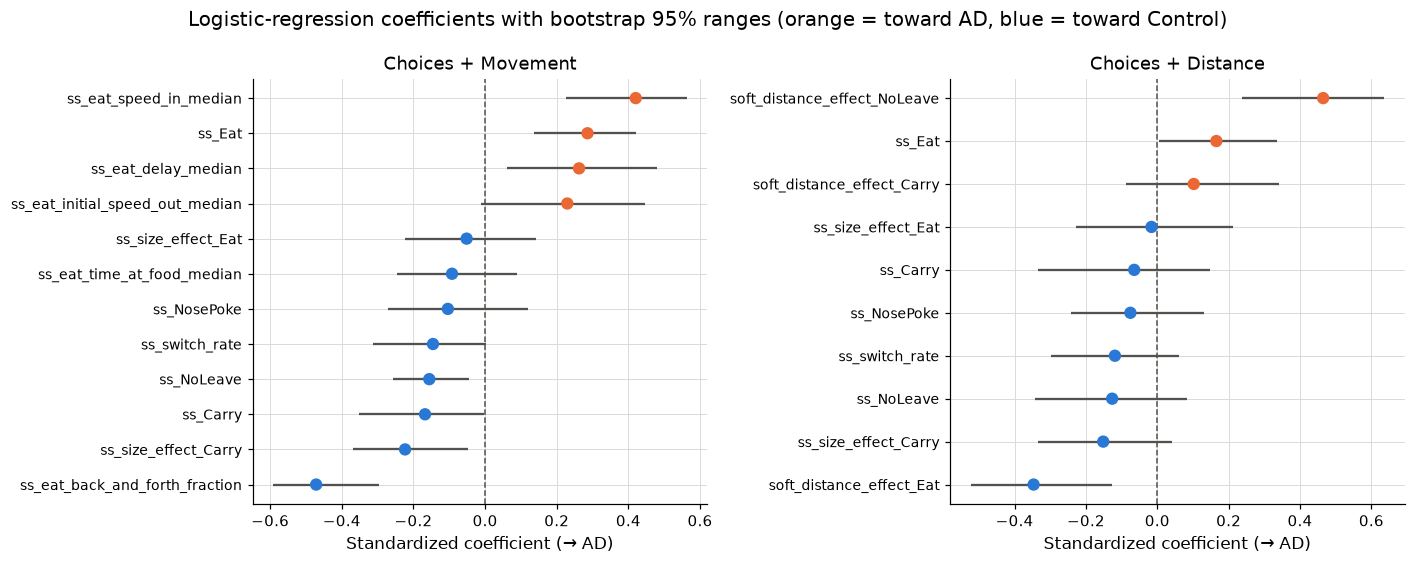

coefficient  low (2.5%)  high (97.5%)  fraction same sign
feature set        feature                                                                                   
Choices + Movement ss_Eat                                 0.286       0.136         0.421               1.000
                   ss_Carry                              -0.168      -0.352        -0.002               0.977
                   ss_NosePoke                           -0.104      -0.270         0.121               0.820
                   ss_NoLeave                            -0.156      -0.257        -0.045               0.990
                   ss_size_effect_Eat                    -0.052      -0.222         0.143               0.664
                   ss_size_effect_Carry                  -0.223      -0.370        -0.047               0.992
                   ss_switch_rate                        -0.146      -0.314         0.001               0.972
                   ss_eat_delay_median                    0.262       0.060         0.479               0.990
                   ss_eat_initial_speed_out_median        0.229      -0.010         0.447               0.967
                   ss_eat_time_at_food_median            -0.092      -0.247         0.089               0.844
                   ss_eat_speed_in_median                 0.420       0.226         0.562               1.000
                   ss_eat_back_and_forth_fraction        -0.472      -0.591        -0.295               1.000
Choices + Distance ss_Eat                                 0.165       0.005         0.335               0.980
                   ss_Carry                              -0.065      -0.335         0.148               0.728
                   ss_NosePoke                           -0.075      -0.241         0.130               0.747
                   ss_NoLeave                            -0.127      -0.342         0.085               0.870
                   ss_size_effect_Eat                    -0.016      -0.229         0.213               0.513
                   ss_size_effect_Carry                  -0.152      -0.334         0.040               0.918
                   ss_switch_rate                        -0.119      -0.298         0.061               0.913
                   soft_distance_effect_Eat              -0.347      -0.523        -0.127               0.997
                   soft_distance_effect_Carry             0.102      -0.088         0.341               0.838
                   soft_distance_effect_NoLeave           0.465       0.237         0.635               0.999

In [11]:
def bootstrap_coefficients(X, y, n_bootstrap=1000, seed=0):
    rng = np.random.default_rng(seed)
    model, _ = modeling.make_group_classifier("Logistic regression")
    model.set_params(classifier__C=0.1)
    full_fit = model.fit(X, y)["classifier"].coef_[0]
    samples = []
    for _ in range(n_bootstrap):
        chosen = rng.choice(len(X), size=len(X), replace=True)
        if y.iloc[chosen].nunique() < 2:         # need both groups in the sample
            continue
        fitted = model.fit(X.iloc[chosen], y.iloc[chosen])
        samples.append(fitted["classifier"].coef_[0])
    samples = np.array(samples)
    return pd.DataFrame({
        "coefficient": full_fit,
        "low (2.5%)": np.quantile(samples, 0.025, axis=0),
        "high (97.5%)": np.quantile(samples, 0.975, axis=0),
        "fraction same sign": (np.sign(samples) == np.sign(full_fit)).mean(axis=0),
    }, index=X.columns)


coefficient_tables = {}
for set_name in ["Choices + Movement", "Choices + Distance"]:
    columns, mice = FEATURE_SETS[set_name]
    rows = has_distance if mice == "36 with distance" else pd.Series(True, index=features.index)
    coefficient_tables[set_name] = bootstrap_coefficients(features.loc[rows, columns], y_all[rows])

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, (set_name, table) in zip(axes, coefficient_tables.items()):
    table = table.sort_values("coefficient")
    positions = np.arange(len(table))
    colors = [viz.GROUP_COLORS["AD"] if c > 0 else viz.GROUP_COLORS["Control"] for c in table["coefficient"]]
    ax.hlines(positions, table["low (2.5%)"], table["high (97.5%)"], color=viz.NEUTRAL_DARK, linewidth=1.5)
    ax.scatter(table["coefficient"], positions, color=colors, s=50, zorder=3)
    ax.axvline(0, color=viz.NEUTRAL_DARK, linewidth=1, linestyle="--")
    ax.set_yticks(positions)
    ax.set_yticklabels(table.index, fontsize=9)
    ax.set_xlabel("Standardized coefficient (→ AD)")
    ax.set_title(set_name)
    ax.grid(axis="x", color=viz.NEUTRAL_LIGHT)
fig.suptitle("Logistic-regression coefficients with bootstrap 95% ranges (orange = toward AD, blue = toward Control)")
fig.tight_layout()
viz.save_figure(fig, "03_coefficients")
plt.show()

pd.concat(coefficient_tables, names=["feature set", "feature"]).round(3)

**How to read the output:** features whose bootstrap range does not cross 0 are used consistently by the model.

**Choices + Movement (41 mice):**
* toward **Control**: more **back-and-forth** trips on Eat trials (the strongest coefficient, consistent in 100 % of bootstrap samples), a larger **size effect on Carry**, more Carry and NoLeave in short-soft, a higher switch rate;
* toward **AD**: faster **inbound speed**, more **eating on the spot** in short-soft, longer **start delay**.

**Choices + Distance (36 mice):**
* the **distance effect on NoLeave** dominates (toward AD), together with a **decrease of eating** with distance;
* the short-soft choice features add little once distance sensitivity is known (their ranges include 0).

### What could this mean biologically? (careful, *predictive* interpretation)
The features that separate the groups fit two themes:
1. **Altered cost sensitivity.** When the travel cost increases (long distance), many AD mice stop leaving home instead of adjusting *how* they forage. Control mice keep foraging. AD mice also adapt less to pellet size: they rarely switch to carrying when the pellet is large.
2. **Reduced behavioral variability / exploration.** AD mice switch less between behaviors and make fewer back-and-forth trips. They tend to commit to eating on the spot. This *could* reflect reduced flexibility or reduced exploratory checking. But a lower switch rate is also partly a mechanical consequence of eating more often: a mouse that eats on 90 % of trials cannot switch often.

These are **hypotheses suggested by a predictive model**, not demonstrated mechanisms. The analysis shows *which* behavioral summaries differ between the groups, not *why*.

## 8. Save results

In [12]:
features.round(4).to_csv(f"{TABLES}/03_mouse_features.csv")
univariate.round(4).to_csv(f"{TABLES}/03_univariate_comparison.csv", index=False)
results.round(3).to_csv(f"{TABLES}/03_group_classification_results.csv", index=False)
permutation_table.round(4).to_csv(f"{TABLES}/03_permutation_tests.csv", index=False)
pd.concat(coefficient_tables, names=["feature set", "feature"]).round(4).to_csv(f"{TABLES}/03_coefficients.csv")
print("Saved.")

Saved.


## 9. Summary and limitations

### Answers to the research questions

**1. Can behavior distinguish Control and AD mice?** Yes, at the level of mice, and clearly better than chance, but only with the right features:

| Feature set | AUC (logistic regression) | vs. chance |
|---|---|---|
| Overall behavior proportions | 0.50 | not different (p = 0.52) |
| Short-soft choices | 0.59 (random forest 0.74) | not significant with logistic regression (p = 0.12) |
| Distance sensitivity (36 mice) | 0.81 | p = 0.006 |
| Movement on Eat trials | 0.81 (random forest 0.89) | p = 0.002 |
| Choices + Movement | 0.89 | p = 0.002 |

**2. Which characteristics contribute most?** The increase of NoLeave with distance; fewer back-and-forth trips; faster return speed; more eating and less carrying in short-soft (including no size-dependent carrying); longer start delays (in about half of the AD mice).

**3. Does condition-dependent behavior help?** Yes, very clearly. Overall proportions carry no information (AUC 0.50), while the *change* of behavior between conditions (distance sensitivity) reaches AUC 0.81 with only three features. How a mouse **reacts** to the task matters more than what it does on average.

**4. Cost sensitivity / flexibility?** The pattern is consistent with **stronger sensitivity to travel cost** (stopping foraging at long distance), **weaker sensitivity to reward size** (no switch to carrying), and **less variable behavior**. All three are hypotheses for further experiments, not conclusions.

### Methodological lessons
* **The mouse is the sample.** Trial-level cross-validation inflated the AUC from 0.67 to 0.80 (section 1).
* **Permutation tests are essential with 41 samples:** chance alone produces AUCs up to ~0.7.
* **Compare like with like:** condition-specific and within-behavior features avoid confounds from unequal condition coverage and different behavior mixes.
* **More features can hurt** with few samples (Choices + Distance < Distance alone).

### Limitations
* **Small sample:** 13 AD mice (10 for distance features). AUCs have wide uncertainty, and several AD features are bimodal: the "AD profile" describes a subset of AD mice particularly well.
* **Movement features and testing period:** the Control group combines mice tested in 2020–21 and in 2022, and the 2022 mice moved very differently (much slower, longer at the food; notebook 01). In an additional check outside this notebook, leaving out the 2022 controls lowered the movement-based AUC from about 0.80 to 0.71 and Choices + Movement from 0.89 to 0.71. Part of the movement-based separation therefore reflects *when and how* the control mice were tested rather than genotype. Choice-based features were barely affected. The movement results should be interpreted with caution.
* **Completed records:** features use each mouse's full behavioral record; this is not early detection.
* **Design confounds:** conditions were presented in blocks, so "distance sensitivity" is also a reaction to the *first change* of condition after many short-soft sessions (notebook 01).
* **Selection:** several feature sets and two models were compared; the single best AUC is slightly optimistic.
* **Association, not mechanism:** none of these results show *why* AD mice behave differently.